In [239]:
import matplotlib.pyplot as plt
import numpy as np
from itertools import product, count
import math
import cmath

In [32]:
def circleverts(radius):
    """Returns list of interior point coordinates and a list of boundary point coordinates"""
    inner = []
    boundary = []
    for (x,y) in product(range(math.ceil(-radius-1),math.ceil(radius+1.01)), range(math.ceil(-radius-1),math.ceil(radius+1.01))):
        if x*x+y*y < radius*radius:
            inner.append((x,y))
        else:
            if x*x+y*y < (radius+1)*(radius+1):
                boundary.append((x,y))
    return inner, boundary

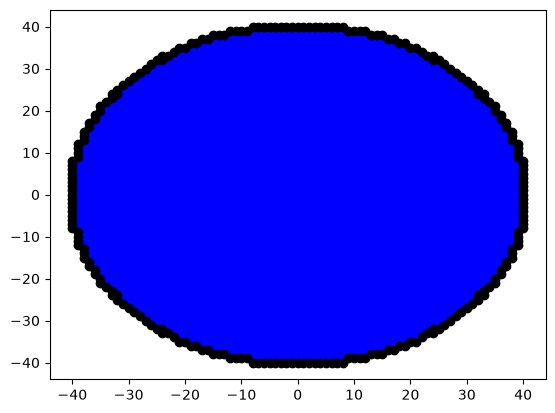

In [265]:
R = 40

interior, boundary = circleverts(R)
ix = [x for (x,y) in interior]
iy = [y for (x,y) in interior]
bx = [x for (x,y) in boundary]
by = [y for (x,y) in boundary]
plt.scatter(ix, iy, color='blue', )
plt.scatter(bx, by, color='black')

In [266]:
def buildmatrix(boundary, interior):
    """from list of boundary coordinates and interior coordinates, build the transistion matrix,
    assuming boundary points are absorbing.  Follows the procedure in Snell and Doyle."""
    u = len(boundary)
    v = len(interior)
    R = np.zeros((v, u))
    Q = np.zeros((v, v))
    intidx = dict(zip(interior, count()))
    bdyidx = dict(zip(boundary, count()))
    for (x,y) in interior:
        #print(x,y)
        inbrs = []
        bnbrs = []
        for (nx,ny) in [(x-1,y), (x+1,y), (x,y-1), (x,y+1)]:
            if (nx, ny) in bdyidx:
                bnbrs.append(bdyidx[(nx, ny)])
            if (nx, ny) in intidx:
                inbrs.append(intidx[(nx, ny)])
        tnbrs = len(inbrs) + len(bnbrs)
        for nidx in bnbrs:
            R[intidx[(x,y)], nidx] += 1/tnbrs
        for nidx in inbrs:
            Q[intidx[(x,y)], nidx] += 1/tnbrs
    #B = np.matmul(np.linalg.inv(np.eye(v)-Q), R) # as in Snell and Doyle, but...
    B = np.linalg.solve(np.eye(v)-Q, R)           # this is better
    return B

In [267]:
%%time
B=buildmatrix(boundary, interior)

CPU times: user 3.65 s, sys: 327 ms, total: 3.98 s
Wall time: 1.19 s


In [268]:
intidx = dict(zip(interior, count()))
bdyidx = dict(zip(boundary, count()))

basex = 20
basept = (-basex,0)
baseidx = intidx[basept]

dists = np.sqrt((np.array(bx) - basept[0]) ** 2 + (np.array(by) - basept[1])**2)

r = np.linspace(0,2*R,200)
harm = r*0
for i in range(len(r)):
    harm[i] = np.dot(B[baseidx], dists < r[i])

xharm = r*0
for i in range(len(r)):
    xharm[i] = exactharm(R, r[i], basex)


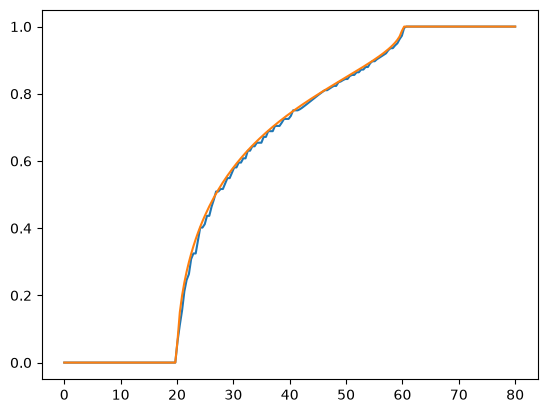

In [269]:
plt.plot(r,harm)
plt.plot(r, xharm)
plt.savefig('harm40.png')

In [246]:
def exactharm(R, r, x0):
    sR = 1
    sr = r/R
    sx0 = x0/R
    if abs(sx0) + sr <= 1:
        return 0
    if 1 + abs(sx0) <= sr:
        return 1
    costheta = (sr**2 - 1 - sx0**2) / (-2*sx0)
    sintheta = math.sqrt(1-costheta**2)
    bz = costheta + 1j*sintheta
    newz = (bz-sx0)*(1-1/sx0)/((bz-1/sx0)*(1-sx0))
    return cmath.phase(newz) / math.pi

In [251]:
exactharm(40, 40, 20)

0.7412918697654988